<a href="https://colab.research.google.com/github/uzmaa29/Pneumonia-Detection/blob/main/pnuemonia_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from fastai import *
from fastai.vision.all import *
from fastai.metrics import error_rate
import pandas as pd
import numpy as np

set_seed(67)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = '/content'

In [3]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:19<00:00, 128MB/s]



In [4]:
!unzip /content/chest-xray-pneumonia.zip -d /content/chest_xray

Streaming output truncated to the last 5000 lines.
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: /content/chest_xray/chest_xray/train/NORMAL/IM-0442-0001.jpeg  


In [5]:
path = Path('/content/chest_xray/chest_xray')

In [6]:
data = ImageDataLoaders.from_folder(
    path,
    train = 'train',
    valid_pct= 0.2,
    seed = 67,
    item_tfms= Resize(224)
)

print('Classes:', data.vocab)
print('Tran Images:', len(data.train_ds))
print('Valid Images:', len(data.valid_ds))

Classes: ['NORMAL', 'PNEUMONIA']
Tran Images: 9370
Valid Images: 2342


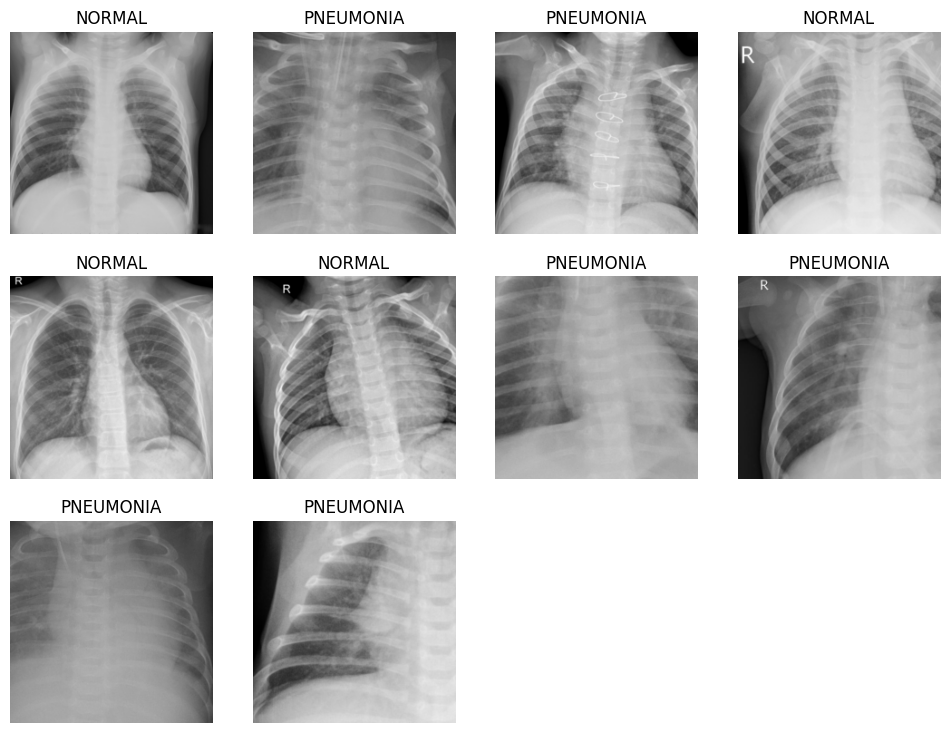

In [7]:
data.show_batch(max_n = 10)

In [8]:
learn = vision_learner(data, models.resnet50, metrics = accuracy)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 159MB/s]


<div></div>

SuggestedLRs(valley=0.0008317637839354575)

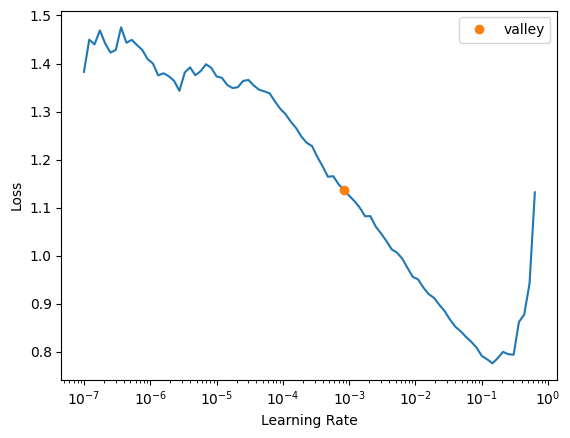

In [9]:
learn.lr_find()

In [10]:
learn.fit_one_cycle(4, slice(1e-3, 1e-1))

epoch,train_loss,valid_loss,accuracy,time
0,0.713751,0.648657,0.931682,03:56
1,0.484702,0.148455,0.969257,04:01
2,0.156836,0.200673,0.970538,04:03
3,0.091798,0.075510,0.972673,04:00


In [12]:
test_files = get_image_files(path/'test')
test_dl = data.test_dl(test_files, with_labels=True)

test_loss, test_acc = learn.validate(dl=test_dl)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Test loss: 0.4054
Test accuracy: 0.9279


              precision    recall  f1-score   support

      NORMAL       0.98      0.82      0.90       234
   PNEUMONIA       0.90      0.99      0.95       390

    accuracy                           0.93       624
   macro avg       0.94      0.91      0.92       624
weighted avg       0.93      0.93      0.93       624



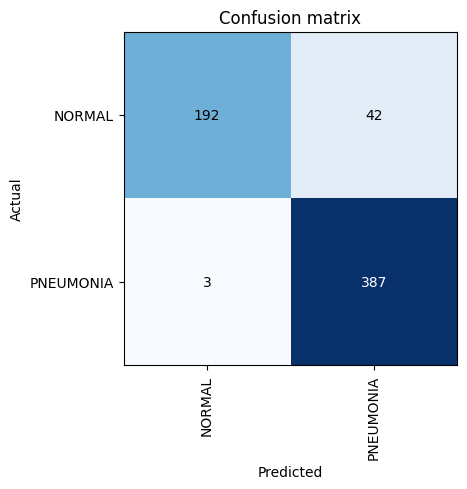

In [13]:
from sklearn.metrics import classification_report

interpret = ClassificationInterpretation.from_learner(learn, dl=test_dl)
interpret.plot_confusion_matrix()

preds, targs = learn.get_preds(dl=test_dl)
y_pred = preds.argmax(dim=1).numpy()
y_true = targs.numpy()

print(classification_report(y_true, y_pred, target_names=data.vocab))

In [14]:
img = PILImage.create('/content/chest_xray/chest_xray/test/NORMAL/IM-0001-0001.jpeg')

<Axes: >

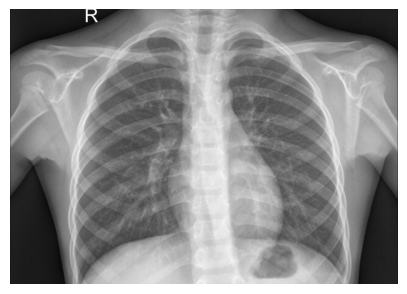

In [15]:
img.show()

In [16]:
print(learn.predict(img)[0])

NORMAL


In [17]:
img = PILImage.create('/content/chest_xray/chest_xray/test/PNEUMONIA/person100_bacteria_482.jpeg')

<Axes: >

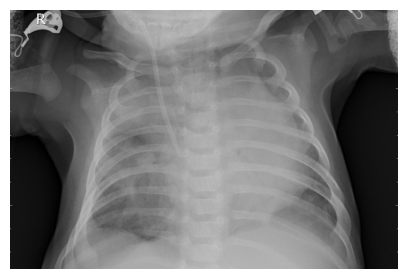

In [18]:
img.show()

In [19]:
print(learn.predict(img)[0])

PNEUMONIA
